# Multimodal stacking

Four base models produce out-of-fold (OOF) probabilities for a logistic-regression meta-model. Embeddings and financial features stay separate until their probabilities are combined. No custom estimator class is needed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

## 1. Load and check data

In [2]:
# Run this notebook from notebooks/notebooks_daniel, as in the other notebooks.
DATA_DIR = Path("../../data")
TRAIN_PATH = DATA_DIR / "processed/df_train_preprocessed.pkl"
VAL_PATH = DATA_DIR / "processed/df_val_preprocessed.pkl"
FINANCIAL_PATH = Path("../../../data/df_financials_train.pkl")

df_train = pd.read_pickle(TRAIN_PATH)
df_val = pd.read_pickle(VAL_PATH)
df_financial = pd.read_pickle(FINANCIAL_PATH)

# Keep one financial row per company and use the first non-null value.
df_financial = df_financial.groupby("id", as_index=False).first()
df_train = df_train.merge(df_financial, on="id", how="left", validate="many_to_one")
df_val = df_val.merge(df_financial, on="id", how="left", validate="many_to_one")

EMBEDDING_COLUMN = "business_description_embedding"
TARGET = "industry"
TABULAR_FEATURES = [
    "country_code",
    "net_profit_margin",
    "ebitda_margin",
    "asset_turnover",
]
missing = set(TABULAR_FEATURES) - set(df_train.columns)
if missing:
    raise KeyError(f"Missing tabular features: {sorted(missing)}")

X_train_emb = np.asarray(df_train[EMBEDDING_COLUMN].tolist(), dtype=np.float32)
X_val_emb = np.asarray(df_val[EMBEDDING_COLUMN].tolist(), dtype=np.float32)
X_train_tab = df_train[TABULAR_FEATURES].copy()
X_val_tab = df_val[TABULAR_FEATURES].copy()
# Ratios can contain +/-inf (for example, division by zero). Cleaning is
# deterministic; the median is still learned separately inside each CV fold.
numeric_features = ["net_profit_margin", "ebitda_margin", "asset_turnover"]
for name, frame in [("train", X_train_tab), ("validation", X_val_tab)]:
    numeric = frame[numeric_features].apply(pd.to_numeric, errors="raise")
    inf_counts = np.isinf(numeric).sum()
    print(f"{name}: infinite ratios replaced with NaN: {inf_counts.to_dict()}")
    frame[numeric_features] = numeric.replace([np.inf, -np.inf], np.nan)
    frame["country_code"] = frame["country_code"].fillna(np.nan)

for name, embeddings in [("train", X_train_emb), ("validation", X_val_emb)]:
    if embeddings.ndim != 2 or not np.isfinite(embeddings).all():
        raise ValueError(f"{name} embeddings must be a finite 2D matrix")

# XGBoost requires consecutive integer class labels; use the same encoding
# for every model. label_encoder.classes_ gives the original industry names.
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train[TARGET])
y_val = label_encoder.transform(df_val[TARGET])
if np.bincount(y_train).min() < 5:
    raise ValueError("Each training class needs at least 5 rows for 5-fold OOF")
print(f"Embeddings: {X_train_emb.shape}; classes: {len(label_encoder.classes_)}")

train: infinite ratios replaced with NaN: {'net_profit_margin': 1779, 'ebitda_margin': 732, 'asset_turnover': 4}
validation: infinite ratios replaced with NaN: {'net_profit_margin': 223, 'ebitda_margin': 81, 'asset_turnover': 1}
Embeddings: (24414, 768); classes: 25


In [3]:
cal_indices, test_indices = train_test_split(
    np.arange(len(y_val)), test_size=0.5, random_state=42, stratify=y_val,
)
y_cal, y_test = y_val[cal_indices], y_val[test_indices]

## 2. Define the four branches

Cosine KNN and standardized logistic regression use embeddings. XGBoost and random forest use country and financial ratios. The expensive probability-enabled RBF SVM is omitted to keep this workflow simpler and faster. Tree models do not need numeric scaling.

Financial cleaning follows `financial_data.ipynb`: replace infinities with missing values; fill with the country median when that country has at least 10 observed values for the feature, otherwise the global median. Missing or unseen countries use the global median. A completely empty fold feature falls back to zero. The small preprocessing class keeps this rule inside cross-validation; stacking itself needs no custom class.


In [4]:
class CountryMedianImputer(TransformerMixin, BaseEstimator):
    """Match financial_data.ipynb, learning medians only from fit rows."""
    def __init__(self, numeric_features, min_support=10):
        self.numeric_features = numeric_features
        self.min_support = min_support

    def fit(self, X, y=None):
        numeric = X[self.numeric_features].replace([np.inf, -np.inf], np.nan)
        # A completely empty feature has no median; use zero as a final fallback.
        self.global_medians_ = numeric.median().fillna(0.0)
        grouped = numeric.groupby(X["country_code"])
        self.country_medians_ = grouped.median().where(grouped.count() >= self.min_support)
        return self

    def transform(self, X):
        result = X.copy()
        for col in self.numeric_features:
            values = result[col].replace([np.inf, -np.inf], np.nan)
            country_medians = result["country_code"].map(self.country_medians_[col])
            result[col] = values.fillna(country_medians).fillna(self.global_medians_[col])
        return result


# Parallelize each model internally; keep CV sequential to avoid nested
# process/thread pools and several copies of the embedding matrix in RAM.
emb_knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=19, metric="cosine", n_jobs=-1)),
])
emb_lr = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=1000)),
])
tabular_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("country", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]), ["country_code"]),
])
tab_xgb = Pipeline([
    ("clean", CountryMedianImputer(numeric_features)),
    ("prep", tabular_preprocessor),
    ("model", XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        objective="multi:softprob", eval_metric="mlogloss",
        tree_method="hist", n_jobs=-1, random_state=42,
    )),
])
# Give each pipeline its own preprocessor, including for the final full-data fit.
tab_rf = Pipeline([
    ("clean", CountryMedianImputer(numeric_features)),
    ("prep", clone(tabular_preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=3,
        n_jobs=-1, random_state=42,
    )),
])

## 3. Generate OOF probabilities and train the meta-model

Five folds mean five fits per branch, followed by one full-data fit. Progress messages identify the current branch. Imputation and scaling are fitted only on the training part of each fold.

In [5]:
# Preflight both tabular pipelines before spending time on embedding OOF.
for model in [tab_xgb, tab_rf]:
    clone(model[:-1]).fit_transform(X_train_tab, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# All branches use the same folds and class order. Each OOF row is predicted
# by a model trained without that row (including preprocessing).
print("OOF: embedding KNN", flush=True)
oof_emb_knn = cross_val_predict(emb_knn, X_train_emb, y_train, cv=cv, method="predict_proba", n_jobs=1)
print("OOF: embedding logistic regression", flush=True)
oof_emb_lr = cross_val_predict(emb_lr, X_train_emb, y_train, cv=cv, method="predict_proba", n_jobs=1)
print("OOF: tabular XGBoost", flush=True)
oof_tab_xgb = cross_val_predict(tab_xgb, X_train_tab, y_train, cv=cv, method="predict_proba", n_jobs=1)
print("OOF: tabular random forest", flush=True)
oof_tab_rf = cross_val_predict(tab_rf, X_train_tab, y_train, cv=cv, method="predict_proba", n_jobs=1)

OOF: embedding KNN
OOF: embedding logistic regression
OOF: tabular XGBoost
OOF: tabular random forest


In [6]:
# Four models times K classes: (n_samples, 4 * K), not necessarily 8.
meta_X = np.hstack([oof_emb_knn, oof_emb_lr, oof_tab_xgb, oof_tab_rf])
meta_model = LogisticRegression(max_iter=1000).fit(meta_X, y_train)
print(f"Meta-feature shape: {meta_X.shape}")

Meta-feature shape: (24414, 100)


## 4. Refit branches and build held-out meta-features

In [7]:
# cross_val_predict fits clones, so fit the original branches on all training
# rows before predicting calibration/evaluation data.
for name, model, X in [
    ("emb_knn", emb_knn, X_train_emb), ("emb_lr", emb_lr, X_train_emb),
    ("tab_xgb", tab_xgb, X_train_tab), ("tab_rf", tab_rf, X_train_tab),
]:
    print(f"Full-data fit: {name}", flush=True)
    model.fit(X, y_train)

def make_meta_features(X_emb, X_tab):
    return np.hstack([
        emb_knn.predict_proba(X_emb), emb_lr.predict_proba(X_emb),
        tab_xgb.predict_proba(X_tab), tab_rf.predict_proba(X_tab),
    ])

calibration_meta = make_meta_features(X_val_emb[cal_indices], X_val_tab.iloc[cal_indices])
test_meta = make_meta_features(X_val_emb[test_indices], X_val_tab.iloc[test_indices])

Full-data fit: emb_knn
Full-data fit: emb_lr
Full-data fit: tab_xgb
Full-data fit: tab_rf



Embedding KNN
Weighted F1:		0.7264
Brier:			0.1575
Combined score:		0.6120
Mean confidence:	0.7319
Accuracy:		0.7325


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",2,0.157895,0.000000
"(0.2, 0.3]",14,0.255639,0.428571
"(0.3, 0.4]",90,0.343860,0.366667
"(0.4, 0.5]",134,0.449332,0.462687
"(0.5, 0.6]",167,0.550898,0.538922
"(0.6, 0.7]",172,0.663097,0.651163
"(0.7, 0.8]",202,0.766024,0.801980
"(0.8, 0.9]",238,0.869084,0.886555
"(0.9, 1.0]",338,0.977733,0.940828


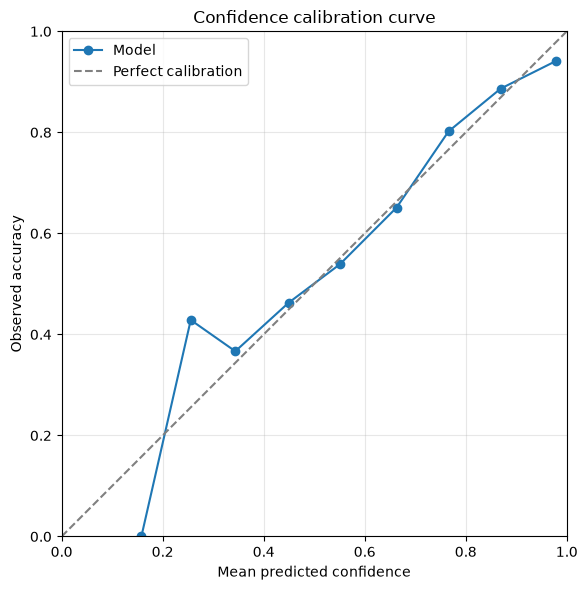


Embedding logistic regression
Weighted F1:		0.6807
Brier:			0.1976
Combined score:		0.5461
Mean confidence:	0.8278
Accuracy:		0.6817


,count,mean_confidence,accuracy
bin,,,
"(0.2, 0.3]",11,0.266269,0.181818
"(0.3, 0.4]",40,0.359499,0.200000
"(0.4, 0.5]",81,0.452119,0.382716
"(0.5, 0.6]",103,0.547901,0.427184
"(0.6, 0.7]",112,0.652517,0.428571
"(0.7, 0.8]",110,0.755830,0.590909
"(0.8, 0.9]",171,0.853694,0.614035
"(0.9, 1.0]",729,0.975010,0.853224


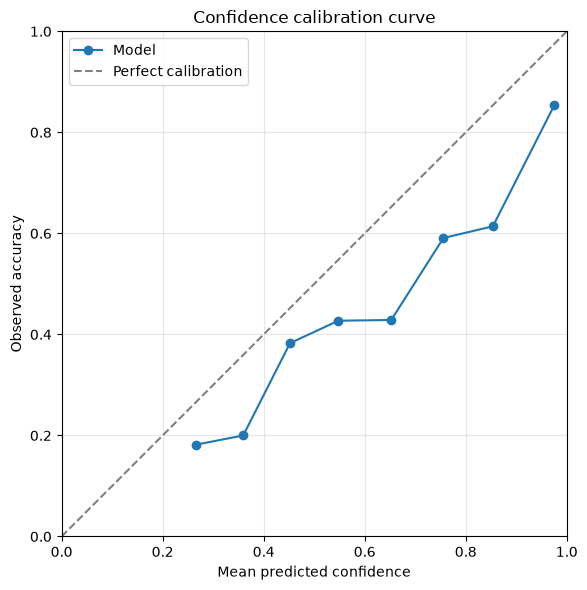


Tabular XGBoost
Weighted F1:		0.2520
Brier:			0.1737
Combined score:		0.2082
Mean confidence:	0.2652
Accuracy:		0.2962


,count,mean_confidence,accuracy
bin,,,
"(-0.001, 0.1]",6,0.095557,0.000000
"(0.1, 0.2]",671,0.150930,0.172876
"(0.2, 0.3]",378,0.236098,0.272487
"(0.3, 0.4]",79,0.343620,0.392405
"(0.4, 0.5]",67,0.435926,0.507463
"(0.5, 0.6]",18,0.543577,0.722222
"(0.6, 0.7]",12,0.637806,0.833333
"(0.7, 0.8]",99,0.719745,0.686869
"(0.8, 0.9]",16,0.843814,1.000000


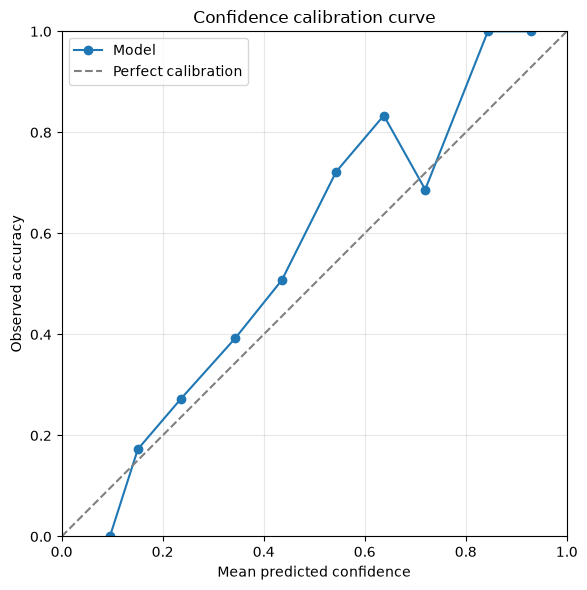


Tabular random forest
Weighted F1:		0.2105
Brier:			0.1771
Combined score:		0.1732
Mean confidence:	0.2030
Accuracy:		0.2786


,count,mean_confidence,accuracy
bin,,,
"(-0.001, 0.1]",14,0.093550,0.071429
"(0.1, 0.2]",970,0.143467,0.181443
"(0.2, 0.3]",197,0.232827,0.395939
"(0.3, 0.4]",58,0.326191,0.551724
"(0.4, 0.5]",11,0.437178,0.909091
"(0.5, 0.6]",31,0.545145,0.838710
"(0.6, 0.7]",76,0.638605,0.723684


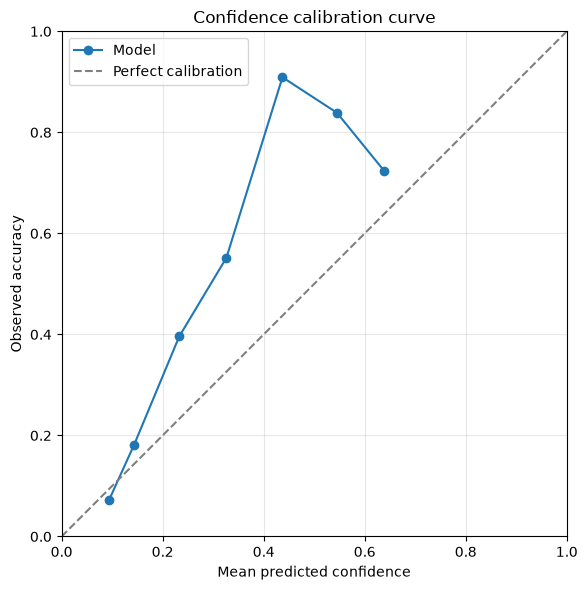

In [12]:
for name, model, X_eval in [
    ("Embedding KNN", emb_knn, X_val_emb[test_indices]),
    ("Embedding logistic regression", emb_lr, X_val_emb[test_indices]),
    ("Tabular XGBoost", tab_xgb, X_val_tab.iloc[test_indices]),
    ("Tabular random forest", tab_rf, X_val_tab.iloc[test_indices]),
]:
    print(f"\n{'=' * 50}\n{name}\n{'=' * 50}")
    evaluate_model(model, X_eval, y_test)

## 5. Calibrate and evaluate

Calibration uses half the validation set with the fitted meta-model frozen. Both versions are then scored on the other half. This is a development comparison; choosing models repeatedly from these scores requires a fresh final test set.

In [8]:
# Freeze the fitted meta-model: only temperature is fitted on calibration rows.
calibrated_meta_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(meta_model), method="temperature",
)
calibrated_meta_model.fit(calibration_meta, y_cal)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",FrozenEstimat...ax_iter=1000))
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'temperature'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...x74ca40108e10

In [ ]:
def evaluate_model(model, X_eval, y_eval, *, calibration_plots=False):
    proba = model.predict_proba(X_eval)
    y_pred = model.classes_[proba.argmax(axis=1)]
    confidence = proba.max(axis=1)
    correct = (y_pred == y_eval).astype(float)
    f1 = f1_score(y_eval, y_pred, average="weighted")
    brier = np.mean((confidence - correct) ** 2)
    print(f"Weighted F1:\t\t{f1:.4f}")
    print(f"Brier:\t\t\t{brier:.4f}")
    print(f"Combined score:\t\t{f1 * (1 - brier):.4f}")
    print(f"Mean confidence:\t{confidence.mean():.4f}")
    print(f"Accuracy:\t\t{correct.mean():.4f}")
    if not calibration_plots:
        return
    calibration = pd.DataFrame({"confidence": confidence, "correct": correct})
    calibration["bin"] = pd.cut(
        calibration["confidence"], bins=np.linspace(0, 1, 11), include_lowest=True
    )
    calibration_stats = calibration.groupby("bin", observed=True).agg(
        count=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        accuracy=("correct", "mean"),
    )
    display(calibration_stats)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(calibration_stats["mean_confidence"], calibration_stats["accuracy"], marker="o", label="Model")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    ax.set(xlabel="Mean predicted confidence", ylabel="Observed accuracy", title="Confidence calibration curve", xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

Uncalibrated stack
Weighted F1:		0.7510
Brier:			0.1454
Combined score:		0.6418
Mean confidence:	0.7615
Accuracy:		0.7531


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",5,0.177595,0.200000
"(0.2, 0.3]",50,0.258227,0.280000
"(0.3, 0.4]",69,0.358233,0.478261
"(0.4, 0.5]",73,0.451381,0.315068
"(0.5, 0.6]",108,0.547139,0.537037
"(0.6, 0.7]",128,0.649959,0.664062
"(0.7, 0.8]",151,0.753707,0.715232
"(0.8, 0.9]",293,0.856408,0.870307
"(0.9, 1.0]",480,0.947647,0.927083


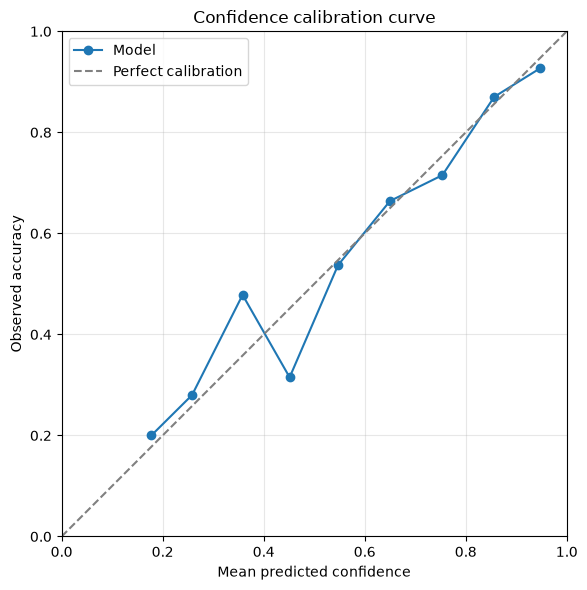

Temperature-calibrated stack
Weighted F1:		0.7510
Brier:			0.1455
Combined score:		0.6417
Mean confidence:	0.7665
Accuracy:		0.7531


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",5,0.179570,0.200000
"(0.2, 0.3]",49,0.260615,0.265306
"(0.3, 0.4]",64,0.358061,0.500000
"(0.4, 0.5]",74,0.449153,0.310811
"(0.5, 0.6]",109,0.549521,0.532110
"(0.6, 0.7]",122,0.651918,0.647541
"(0.7, 0.8]",148,0.753234,0.709459
"(0.8, 0.9]",290,0.857414,0.862069
"(0.9, 1.0]",496,0.949022,0.929435


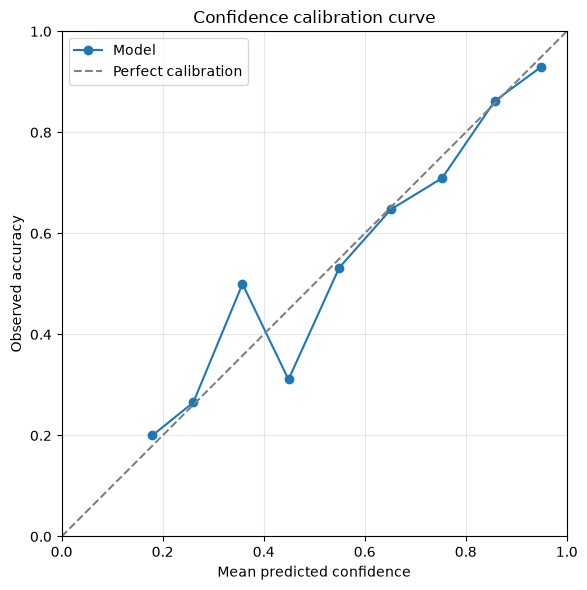

In [10]:
print("Uncalibrated stack")
evaluate_model(meta_model, test_meta, y_test)

print("Temperature-calibrated stack")
evaluate_model(calibrated_meta_model, test_meta, y_test)

The Brier value here measures selected-class confidence against correctness, rather than the full multiclass probability vector. The combined score is weighted F1 × (1 − confidence Brier).